In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv("retail_sales_training_dataset.csv");

#descritive statistics
df.describe()

,Quantity,Unit_Price_ZAR,Discount_Rate
count,503.000000,503.000000,503.000000
mean,2.932406,45.367256,0.038966
std,1.389848,28.551887,0.047261
min,1.000000,8.990000,0.000000
25%,2.000000,19.990000,0.000000
50%,3.000000,42.000000,0.000000
75%,4.000000,59.990000,0.100000
max,5.000000,119.000000,0.150000


In [ ]:
#number of columns and rows
df.shape

(503, 11)

In [ ]:
#first five records
df.head()

,Order_ID,Order_Date,Customer_ID,Product,Category,Region,Quantity,Unit_Price_ZAR,Discount_Rate,Sales_Channel,Payment_Method
0,ORD-10001,2025-02-01,CUST-1084,Hoodie,Clothing,NaN,3,44.99,0.10,Marketplace,EFT
1,ORD-10002,2025-07-02,CUST-1045,Perfume,Beauty,Free State,1,64.99,0.00,In-store,EFT
2,ORD-10003,2025-11-21,CUST-1008,Blender,Home & Kitchen,Eastern Cape,2,49.99,0.05,In-store,EFT
3,ORD-10004,2025-09-05,CUST-1094,Coffee Maker,Home & Kitchen,Western Cape,5,89.99,0.10,Online,Card
4,ORD-10005,2025-05-14,CUST-1117,Headphones,Electronics,Gauteng,4,59.99,0.05,Online,Card


In [ ]:
#list of columns - column names
df.columns.to_list()

['Order_ID',
 'Order_Date',
 'Customer_ID',
 'Product',
 'Category',
 'Region',
 'Quantity',
 'Unit_Price_ZAR',
 'Discount_Rate',
 'Sales_Channel',
 'Payment_Method']

In [ ]:
#see the data types and which columns are empty or consists of null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        503 non-null    str    
 1   Order_Date      503 non-null    str    
 2   Customer_ID     498 non-null    str    
 3   Product         503 non-null    str    
 4   Category        503 non-null    str    
 5   Region          496 non-null    str    
 6   Quantity        503 non-null    int64  
 7   Unit_Price_ZAR  503 non-null    float64
 8   Discount_Rate   503 non-null    float64
 9   Sales_Channel   503 non-null    str    
 10  Payment_Method  503 non-null    str    
dtypes: float64(2), int64(1), str(8)
memory usage: 43.4 KB


In [ ]:
# Count missing values in each column
missing_value = df.isnull().sum()
print(missing_value)

Order_ID          0
Order_Date        0
Customer_ID       5
Product           0
Category          0
Region            7
Quantity          0
Unit_Price_ZAR    0
Discount_Rate     0
Sales_Channel     0
Payment_Method    0
dtype: int64


In [ ]:
missing_percentage = (df.isnull().mean()*100).round(2)
print(missing_percentage)

Order_ID          0.00
Order_Date        0.00
Customer_ID       0.99
Product           0.00
Category          0.00
Region            1.39
Quantity          0.00
Unit_Price_ZAR    0.00
Discount_Rate     0.00
Sales_Channel     0.00
Payment_Method    0.00
dtype: float64


In [ ]:
#Count duplicate rows
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  3


In [ ]:
#Insert duplicate order IDs
duplicates = df[df.duplicated(subset=["Order_ID"], keep = False)]

duplicates.sort_values("Order_ID")

,Order_ID,Order_Date,Customer_ID,Product,Category,Region,Quantity,Unit_Price_ZAR,Discount_Rate,Sales_Channel,Payment_Method
21,ORD-10022,2025-05-13,CUST-1100,Storage Set,Home & Kitchen,Eastern Cape,3,24.99,0.0,Online,Cash
500,ORD-10022,2025-05-13,CUST-1100,Storage Set,Home & Kitchen,Eastern Cape,3,24.99,0.0,Online,Cash
88,ORD-10089,2025-04-19,CUST-1005,Hoodie,Clothing,Eastern Cape,2,44.99,0.0,In-store,Digital Wallet
501,ORD-10089,2025-04-19,CUST-1005,Hoodie,Clothing,Eastern Cape,2,44.99,0.0,In-store,Digital Wallet
143,ORD-10144,2025-10-15,CUST-1076,Storage Set,Home & Kitchen,Gauteng,1,24.99,0.0,Marketplace,Card
502,ORD-10144,2025-10-15,CUST-1076,Storage Set,Home & Kitchen,Gauteng,1,24.99,0.0,Marketplace,Card


In [ ]:
# Examine sales channel values
print(df["Sales_Channel"].value_counts())

# Examine regions
print(df["Region"].value_counts(dropna=False))

# Examine payment methods
print(df["Payment_Method"].value_counts())

Sales_Channel
Online         239
In-store       172
Marketplace     88
online           4
Name: count, dtype: int64
Region
Gauteng          154
Western Cape     118
KwaZulu-Natal    101
Eastern Cape      74
Free State        49
NaN                7
Name: count, dtype: int64
Payment_Method
Card              251
EFT                96
Cash               90
Digital Wallet     66
Name: count, dtype: int64


In [ ]:
print("Cleaning the dataset")

Cleaning the dataset


In [ ]:
# Creating a copy of the dataset, deleting the original is not advisable in professional setting
df_clean = df.drop_duplicates()
df_clean.head()

,Order_ID,Order_Date,Customer_ID,Product,Category,Region,Quantity,Unit_Price_ZAR,Discount_Rate,Sales_Channel,Payment_Method
0,ORD-10001,2025-02-01,CUST-1084,Hoodie,Clothing,NaN,3,44.99,0.10,Marketplace,EFT
1,ORD-10002,2025-07-02,CUST-1045,Perfume,Beauty,Free State,1,64.99,0.00,In-store,EFT
2,ORD-10003,2025-11-21,CUST-1008,Blender,Home & Kitchen,Eastern Cape,2,49.99,0.05,In-store,EFT
3,ORD-10004,2025-09-05,CUST-1094,Coffee Maker,Home & Kitchen,Western Cape,5,89.99,0.10,Online,Card
4,ORD-10005,2025-05-14,CUST-1117,Headphones,Electronics,Gauteng,4,59.99,0.05,Online,Card


In [ ]:
# Standardise sales channel values
df_clean["Sales_Channel"] = (df_clean["Sales_Channel"].str.strip().str.title())


# Handling missing regions
df_clean["Region"] = df_clean["Region"].fillna("Unknown")

# Convert order dates to datetime
df_clean["Order_Date"] = pd.to_datetime(df_clean["Order_Date"])

print("Original records: ", len(df))
print("Cleaned records: ", len(df_clean))

Original records:  503
Cleaned records:  500


In [ ]:
print("Validate the cleaned dataset")

Validate the cleaned dataset


In [ ]:
print("Remaining duplicates: ", df_clean.duplicated().sum())

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nSales channels:")
print(df_clean["Sales_Channel"].value_counts())


Remaining duplicates:  0

Missing values:
Order_ID          0
Order_Date        0
Customer_ID       5
Product           0
Category          0
Region            0
Quantity          0
Unit_Price_ZAR    0
Discount_Rate     0
Sales_Channel     0
Payment_Method    0
dtype: int64

Sales channels:
Sales_Channel
Online         242
In-Store       171
Marketplace     87
Name: count, dtype: int64


In [ ]:
df_clean.head()

,Order_ID,Order_Date,Customer_ID,Product,Category,Region,Quantity,Unit_Price_ZAR,Discount_Rate,Sales_Channel,Payment_Method
0,ORD-10001,2025-02-01,CUST-1084,Hoodie,Clothing,Unknown,3,44.99,0.10,Marketplace,EFT
1,ORD-10002,2025-07-02,CUST-1045,Perfume,Beauty,Free State,1,64.99,0.00,In-Store,EFT
2,ORD-10003,2025-11-21,CUST-1008,Blender,Home & Kitchen,Eastern Cape,2,49.99,0.05,In-Store,EFT
3,ORD-10004,2025-09-05,CUST-1094,Coffee Maker,Home & Kitchen,Western Cape,5,89.99,0.10,Online,Card
4,ORD-10005,2025-05-14,CUST-1117,Headphones,Electronics,Gauteng,4,59.99,0.05,Online,Card


In [ ]:
print("Data Transformation")

Data Transformation


In [ ]:
# Calculating gross sales
df_clean["Gross_Sales"] = (df_clean["Quantity"] * df_clean["Unit_Price_ZAR"])

In [ ]:
# Calculating discount amount
df_clean["Discount_Amount"] = (df_clean["Gross_Sales"] * df_clean["Discount_Rate"])

In [ ]:
# Calculating net revenue
df_clean["Revenue"] = (df_clean["Gross_Sales"] - df_clean["Discount_Amount"])

In [ ]:
# Extract month and year
df_clean["Month"] = df_clean["Order_Date"].dt.month_name()

df_clean["Year"] = df_clean["Order_Date"].dt.year

df_clean["Month_Number"] = df_clean["Order_Date"].dt.month

In [ ]:
df_clean.head(10)

,Order_ID,Order_Date,Customer_ID,Product,Category,Region,Quantity,Unit_Price_ZAR,Discount_Rate,Sales_Channel,Payment_Method,Gross_Sales,Discount_Amount,Revenue,Month,Year,Month_Number
0,ORD-10001,2025-02-01,CUST-1084,Hoodie,Clothing,Unknown,3,44.99,0.10,Marketplace,EFT,134.97,13.497,121.473,February,2025,2
1,ORD-10002,2025-07-02,CUST-1045,Perfume,Beauty,Free State,1,64.99,0.00,In-Store,EFT,64.99,0.000,64.990,July,2025,7
2,ORD-10003,2025-11-21,CUST-1008,Blender,Home & Kitchen,Eastern Cape,2,49.99,0.05,In-Store,EFT,99.98,4.999,94.981,November,2025,11
3,ORD-10004,2025-09-05,CUST-1094,Coffee Maker,Home & Kitchen,Western Cape,5,89.99,0.10,Online,Card,449.95,44.995,404.955,September,2025,9
4,ORD-10005,2025-05-14,CUST-1117,Headphones,Electronics,Gauteng,4,59.99,0.05,Online,Card,239.96,11.998,227.962,May,2025,5
5,ORD-10006,2025-05-01,CUST-1028,Keyboard,Electronics,KwaZulu-Natal,1,34.50,0.00,Online,Digital Wallet,34.50,0.000,34.500,May,2025,5
6,ORD-10007,2025-06-08,CUST-1097,T-Shirt,Clothing,Gauteng,2,19.99,0.10,Online,EFT,39.98,3.998,35.982,June,2025,6
7,ORD-10008,2025-10-18,CUST-1095,USB-C Hub,Electronics,KwaZulu-Natal,1,42.00,0.00,In-Store,EFT,42.00,0.000,42.000,October,2025,10
8,ORD-10009,2025-03-31,CUST-1014,Air Fryer,Home & Kitchen,KwaZulu-Natal,3,119.00,0.00,Online,Cash,357.00,0.000,357.000,March,2025,3
9,ORD-10010,2025-02-03,CUST-1068,Hoodie,Clothing,Gauteng,4,44.99,0.05,Online,Card,179.96,8.998,170.962,February,2025,2


In [ ]:
print("Implementing Explaratory Data Analysis")

Implementing Explaratory Data Analysis


In [ ]:
# Find the best performing products
product_analysis = (df_clean.groupby("Product")["Revenue"].sum().sort_values(ascending=False))

print(product_analysis)

Product
Air Fryer           9585.4500
Coffee Maker        7802.1330
Sneakers            6191.2260
Perfume             5891.3435
Headphones          5543.0760
Jeans               5086.5750
Blender             4566.5865
Hoodie              4292.0460
USB-C Hub           3817.8000
Keyboard            3727.7250
Wireless Mouse      2291.1435
Storage Set         2057.9265
T-Shirt             2012.9930
Face Moisturiser    1247.9155
Sunscreen            942.9750
Shampoo              519.6220
Name: Revenue, dtype: float64


In [ ]:
# Analyse sales by region
region_analysis = (df_clean.groupby("Region")["Revenue"].sum().sort_values(ascending = False))

print(region_analysis)


Region
Gauteng          21191.1215
Western Cape     14510.1160
KwaZulu-Natal    12066.9990
Eastern Cape      9186.7530
Free State        7234.7790
Unknown           1386.7680
Name: Revenue, dtype: float64


In [ ]:
# Analyse sales channels
channel_analysis = (df_clean.groupby("Sales_Channel")["Revenue"].sum().sort_values(ascending=False))

print(channel_analysis)

Sales_Channel
Online         31462.1330
In-Store       21924.7510
Marketplace    12189.6525
Name: Revenue, dtype: float64


In [ ]:
print("Calculating business KPIs")

Calculating business KPIs


In [ ]:
total_revenue = df_clean["Revenue"].sum()

gross_sales = df_clean["Gross_Sales"].sum()

total_order = df_clean["Order_ID"].nunique()

units_sold = df_clean["Quantity"].sum()

average_order_value = total_revenue / total_order

average_discount = df_clean["Discount_Rate"].mean() * 100

unique_customers = df_clean["Customer_ID"].nunique()

kpi_summary = pd.DataFrame({
        "KPI" : [
            "Total Revenue",
            "Gross Sales",
            "Total Orders",
            "Units Sold",
            "Average Order Value",
            "Average Discount (%)",
            "Unique Customers"
        ],
        "Value" : [
            total_revenue,
            gross_sales,
            total_order,
            units_sold,
            average_order_value,
            average_discount,
            unique_customers
        ]
})

kpi_summary

,KPI,Value
0,Total Revenue,65576.536500
1,Gross Sales,68114.950000
2,Total Orders,500.000000
3,Units Sold,1469.000000
4,Average Order Value,131.153073
5,Average Discount (%),3.920000
6,Unique Customers,116.000000


In [ ]:
print("Visualisation")

Visualisation


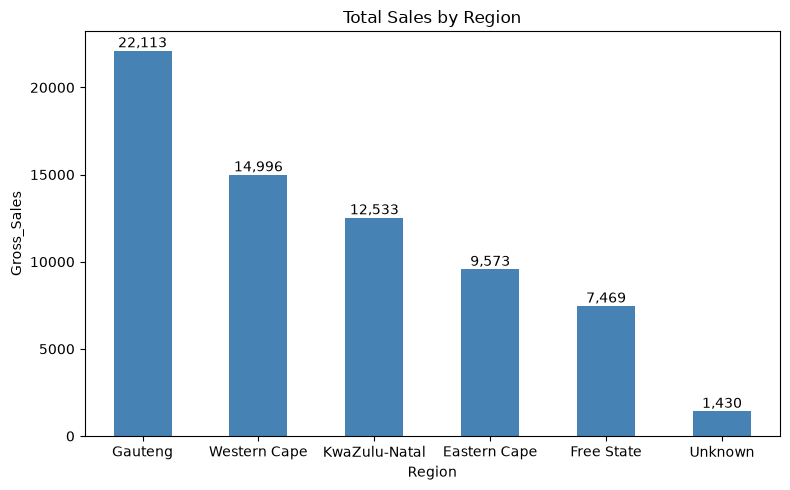

In [ ]:
import matplotlib.pyplot as plt

sales_by_region = (
    df_clean.groupby("Region")["Gross_Sales"]
    .sum()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 5))
sales_by_region.plot(kind="bar", ax=ax, color="steelblue")

ax.set_title("Total Sales by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Gross_Sales")
ax.tick_params(axis="x", rotation=0)

# Show each bar's value on top of it
for i, v in enumerate(sales_by_region):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

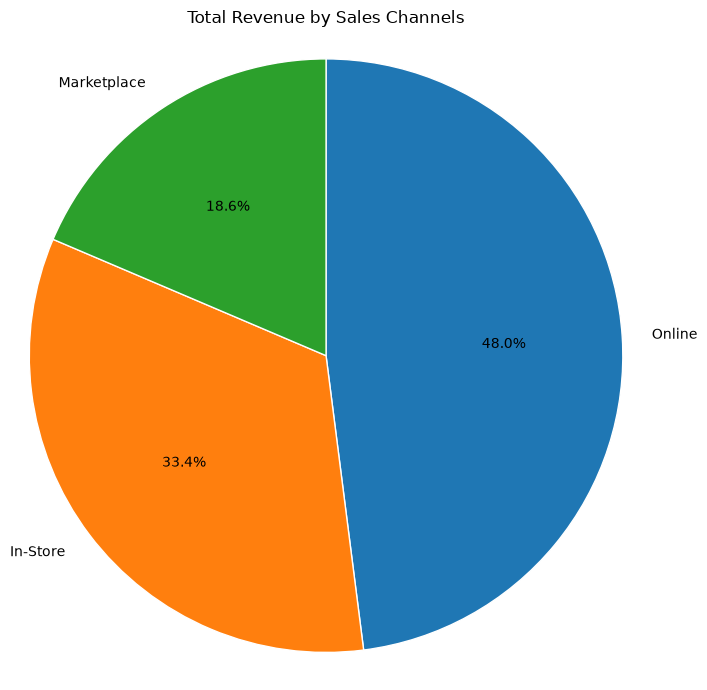

In [ ]:
channels_by_region = df_clean.groupby("Sales_Channel")["Revenue"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    channels_by_region,
    labels=channels_by_region.index,
    autopct="%1.1f%%",   # shows each region's percentage share
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white"},
)
ax.set_title("Total Revenue by Sales Channels")
ax.axis("equal")  # keeps the pie circular
plt.tight_layout()
plt.show()